In [2]:
import re
import os
import random

os.environ["KERAS_BACKEND"] = "tensorflow"

from glob import glob

import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow import keras
from keras import layers
import matplotlib.pyplot as plt
from IPython import display
from jiwer import wer

#### Convert and split the dataset stored in ISSAI_USC to a pandas dataframe

In [3]:
# saveto = "./ISSAI_USC/test"
# wavs = glob("{}/**/*.wav".format(saveto), recursive=True)
# id_to_text =  [file.split('.wav')[0] + '.txt' for file in wavs]

# def get_data(id_to_text, maxlen=250):
#     data = []
#     for w in id_to_text:
#         with open(w) as f: 
#             txt = f.read()
#             txt = txt.replace("o'",'O')
#             txt = txt.replace("g'",'G')
#             data.append(txt)
            
#     return data

# df = pd.DataFrame({
#     'file_name' : wavs,
#     'normalized_transcription' : get_data(id_to_text)
# })
# df

In [4]:
def generate_files(saveto):
    wavs = glob("{}/**/*.wav".format(saveto), recursive=True)
    id_to_text =  [file.split('.wav')[0] + '.txt' for file in wavs]
    return wavs, id_to_text

def get_data(saveto, maxlen=250):
    data = []
    wavs, id_to_text = generate_files(saveto)
    for w in id_to_text:
        with open(w) as f: 
            txt = f.read()
            txt = txt.replace("o'",'O') # mapping o' to o
            txt = txt.replace("g'",'G') # mapping g' to g
            data.append(txt)

    df = pd.DataFrame({
        'file_name' : wavs,
        'normalized_transcription' : data
    })
            
    return df


# df = get_data('./ISSAI_USC/test')
df_train_full = get_data('./ISSAI_USC/train')
df_train = df_train_full[:int(len(df_train_full)*0.10)]
df_val = get_data('./ISSAI_USC/test')

In [5]:
# split = int(len(df) * 0.90)
# df_train = df[:split]
# df_val = df[split:]


print(f"Size of the training set: {len(df_train)}")
print(f"Size of the testing set: {len(df_val)}")

Size of the training set: 10076
Size of the testing set: 3837


#### Tokenize each letter to the coresponding number to generate the vocabulary

In [6]:
characters = [x for x in "abcdefghijklmnopqrstuvwxyzGO "]
char_to_num = keras.layers.StringLookup(vocabulary=characters, oov_token="")
num_to_char = keras.layers.StringLookup(
    vocabulary=char_to_num.get_vocabulary(), oov_token="", invert=True
)

print(f"The vocabulary is: {char_to_num.get_vocabulary()}")
print(f"Size = {char_to_num.vocabulary_size()}")


The vocabulary is: ['', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z', 'G', 'O', ' ']
Size = 30


I0000 00:00:1734374473.414056  353271 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 22335 MB memory:  -> device: 0, name: NVIDIA RTX A5500, pci bus id: 0000:17:00.0, compute capability: 8.6


In [ ]:
frame_length = 256
frame_step = 160
fft_length = 384

In [ ]:

def encode_single_sample(wav_file, label):
    # 1. Read wav file
    file = tf.io.read_file(wav_file)
    # 2. Decode the wav file
    audio, _ = tf.audio.decode_wav(file)
    audio = tf.squeeze(audio, axis=-1)
    # 3. Change type to float
    audio = tf.cast(audio, tf.float32)
    # 4. Get the spectrogram
    spectrogram = tf.signal.stft(
        audio, frame_length=frame_length, frame_step=frame_step, fft_length=fft_length
    )
    # 5. We only need the magnitude, which can be derived by applying tf.abs
    spectrogram = tf.abs(spectrogram)
    spectrogram = tf.math.pow(spectrogram, 0.5)
    # 6. normalisation
    means = tf.math.reduce_mean(spectrogram, 1, keepdims=True)
    stddevs = tf.math.reduce_std(spectrogram, 1, keepdims=True)
    spectrogram = (spectrogram - means) / (stddevs + 1e-10)
    # 7. Convert label to Lower case
    label = tf.strings.lower(label)
    # 8. Split the label
    label = tf.strings.unicode_split(label, input_encoding="UTF-8")
    # 9. Map the characters in label to numbers
    label = char_to_num(label)
    # 10. Return a dict as our model is expecting two inputs
    return spectrogram, label

In [ ]:
batch_size = 32
train_dataset = tf.data.Dataset.from_tensor_slices(
    (list(df_train["file_name"]), list(df_train["normalized_transcription"]))
)
train_dataset = (
    train_dataset.map(encode_single_sample, num_parallel_calls=tf.data.AUTOTUNE)
    .padded_batch(batch_size)
    .prefetch(buffer_size=tf.data.AUTOTUNE)
)

validation_dataset = tf.data.Dataset.from_tensor_slices(
    (list(df_val["file_name"]), list(df_val["normalized_transcription"]))
)
validation_dataset = (
    validation_dataset.map(encode_single_sample, num_parallel_calls=tf.data.AUTOTUNE)
    .padded_batch(batch_size)
    .prefetch(buffer_size=tf.data.AUTOTUNE)
)


2024-12-16 13:41:16.459178: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


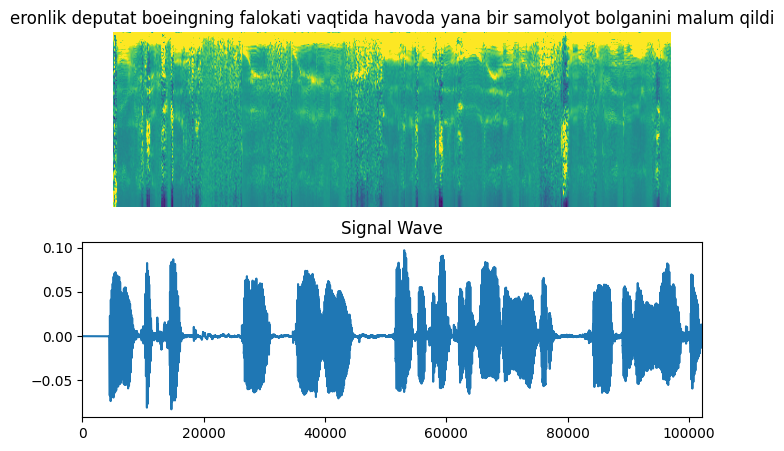

In [ ]:
fig = plt.figure(figsize=(8, 5))
for batch in train_dataset.take(1):
    spectrogram = batch[0][0].numpy()
    spectrogram = np.array([np.trim_zeros(x) for x in np.transpose(spectrogram)])
    label = batch[1][0]
    label = tf.strings.reduce_join(num_to_char(label)).numpy().decode("utf-8")
    ax = plt.subplot(2, 1, 1)
    ax.imshow(spectrogram, vmax=1)
    ax.set_title(label)
    ax.axis("off")
    file = tf.io.read_file(list(df_train["file_name"])[0])
    audio, _ = tf.audio.decode_wav(file)
    audio = audio.numpy()
    ax = plt.subplot(2, 1, 2)
    plt.plot(audio)
    ax.set_title("Signal Wave")
    ax.set_xlim(0, len(audio))
    display.display(display.Audio(np.transpose(audio), rate=16000))
plt.show()

In [ ]:
def CTCLoss(y_true, y_pred):
    batch_len = tf.cast(tf.shape(y_true)[0], dtype="int64")
    input_length = tf.cast(tf.shape(y_pred)[1], dtype="int64")
    label_length = tf.cast(tf.shape(y_true)[1], dtype="int64")

    input_length = input_length * tf.ones(shape=(batch_len, 1), dtype="int64")
    label_length = label_length * tf.ones(shape=(batch_len, 1), dtype="int64")

    loss = keras.backend.ctc_batch_cost(y_true, y_pred, input_length, label_length)
    return loss


In [ ]:
def build_model(input_dim, output_dim, rnn_layers=5, rnn_units=128):
    # Model's input
    input_spectrogram = layers.Input((None, input_dim), name="input")
    # Expand the dimension to use 2D CNN.
    x = layers.Reshape((-1, input_dim, 1), name="expand_dim")(input_spectrogram)
    # Convolution layer 1
    x = layers.Conv2D(
        filters=32,
        kernel_size=[11, 41],
        strides=[2, 2],
        padding="same",
        use_bias=False,
        name="conv_1",
    )(x)
    x = layers.BatchNormalization(name="conv_1_bn")(x)
    x = layers.ReLU(name="conv_1_relu")(x)
    # Convolution layer 2
    x = layers.Conv2D(
        filters=32,
        kernel_size=[11, 21],
        strides=[1, 2],
        padding="same",
        use_bias=False,
        name="conv_2",
    )(x)
    x = layers.BatchNormalization(name="conv_2_bn")(x)
    x = layers.ReLU(name="conv_2_relu")(x)
    # Reshape the resulted volume to feed the RNNs layers
    x = layers.Reshape((-1, x.shape[-2] * x.shape[-1]))(x)
    # RNN layers
    for i in range(1, rnn_layers + 1):
        recurrent = layers.GRU(
            units=rnn_units,
            activation="tanh",
            recurrent_activation="sigmoid",
            use_bias=True,
            return_sequences=True,
            reset_after=True,
            name=f"gru_{i}",
        )
        x = layers.Bidirectional(
            recurrent, name=f"bidirectional_{i}", merge_mode="concat"
        )(x)
        if i < rnn_layers:
            x = layers.Dropout(rate=0.5)(x)
    # Dense layer
    x = layers.Dense(units=rnn_units * 2, name="dense_1")(x)
    x = layers.ReLU(name="dense_1_relu")(x)
    x = layers.Dropout(rate=0.5)(x)
    # Classification layer
    output = layers.Dense(units=output_dim + 1, activation="softmax")(x)
    # Model
    model = keras.Model(input_spectrogram, output, name="DeepSpeech_2")
    # Optimizer
    opt = keras.optimizers.Adam(learning_rate=1e-4)
    # Compile the model and return
    model.compile(optimizer=opt, 
                  loss=CTCLoss)
    return model


# Get the model
model = build_model(
    input_dim=fft_length // 2 + 1,
    output_dim=char_to_num.vocabulary_size(),
    rnn_units=512,
)
model.summary(line_length=110)

Model: "DeepSpeech_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                                   ┃ Output Shape                        ┃             Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩
│ input (InputLayer)                             │ (None, None, 193)                   │                   0 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ expand_dim (Reshape)                           │ (None, None, 193, 1)                │                   0 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ conv_1 (Conv2D)                                │ (None, None, 97, 32)                │              14,432 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ conv_1_bn (BatchNormalization)                 │ (None, None, 97, 32)                │                 128 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ conv_1_relu (ReLU)                             │ (None, None, 97, 32)                │                   0 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ conv_2 (Conv2D)                                │ (None, None, 49, 32)                │             236,544 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ conv_2_bn (BatchNormalization)                 │ (None, None, 49, 32)                │                 128 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ conv_2_relu (ReLU)                             │ (None, None, 49, 32)                │                   0 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ reshape (Reshape)                              │ (None, None, 1568)                  │                   0 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ bidirectional_1 (Bidirectional)                │ (None, None, 1024)                  │           6,395,904 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ dropout (Dropout)                              │ (None, None, 1024)                  │                   0 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ bidirectional_2 (Bidirectional)                │ (None, None, 1024)                  │           4,724,736 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ dropout_1 (Dropout)                            │ (None, None, 1024)                  │                   0 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ bidirectional_3 (Bidirectional)                │ (None, None, 1024)                  │           4,724,736 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ dropout_2 (Dropout)                            │ (None, None, 1024)                  │                   0 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ bidirectional_4 (Bidirectional)                │ (None, None, 1024)                  │           4,724,736 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ dropout_3 (Dropout)                            │ (None, None, 1024)                  │                   0 │
├───

 Total params: 26,627,455 (101.58 MB)

 Trainable params: 26,627,327 (101.58 MB)

 Non-trainable params: 128 (512.00 B)

In [ ]:
def decode_batch_predictions(pred):
    input_len = np.ones(pred.shape[0]) * pred.shape[1]
    results = keras.backend.ctc_decode(pred, input_length=input_len, greedy=True)[0][0]
    output_text = []
    for result in results:
        result = tf.strings.reduce_join(num_to_char(result)).numpy().decode("utf-8")
        output_text.append(result)
    return output_text

In [ ]:
class CallbackEval(keras.callbacks.Callback):
    """Displays a batch of outputs after every epoch."""

    def __init__(self, dataset):
        super().__init__()
        self.dataset = dataset

    def on_epoch_end(self, epoch: int, logs=None):
        predictions = []
        targets = []
        for batch in self.dataset:
            X, y = batch
            batch_predictions = model.predict(X)
            batch_predictions = decode_batch_predictions(batch_predictions)
            predictions.extend(batch_predictions)
            for label in y:
                label = (
                    tf.strings.reduce_join(num_to_char(label)).numpy().decode("utf-8")
                )
                targets.append(label)
        wer_score = wer(targets, predictions)
        print("-" * 100)
        print(f"Word Error Rate: {wer_score:.4f}")
        print("-" * 100)
        for i in np.random.randint(0, len(predictions), 2):
            print(f"Target    : {targets[i]}")
            print(f"Prediction: {predictions[i]}")
            print("-" * 100)

In [ ]:
epochs = 30
validation_callback = CallbackEval(validation_dataset)

# with tf.device('/CPU:0'):
#     history = model.fit(
#         train_dataset,
#         validation_data=validation_dataset,
#         epochs=epochs,
#         callbacks=[validation_callback],
#     )

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=epochs,
    callbacks=[validation_callback],
)


Epoch 1/30


I0000 00:00:1734374486.786430  353415 cuda_dnn.cc:530] Loaded cuDNN version 90300
W0000 00:00:1734374486.857367  353415 cuda_executor.cc:270] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1734374486.937988  353415 cuda_executor.cc:270] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1734374486.952111  353415 cuda_executor.cc:270] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1734374486.957713  353415 cuda_executor.cc:270] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1734374486.964114  353415 cuda_executor.cc:270] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1734374486.967888  353415 cuda_executor.cc:270] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1734374487.026638  353415 cuda_executor.cc:270] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1734374487.031589  353415 cuda_executo

  1/315 ━━━━━━━━━━━━━━━━━━━━ 1:00:35 12s/step - loss: 1617.0710

W0000 00:00:1734374493.797215  353413 cuda_executor.cc:270] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1734374493.841004  353413 cuda_executor.cc:270] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1734374493.844785  353413 cuda_executor.cc:270] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1734374493.848521  353413 cuda_executor.cc:270] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1734374493.851248  353413 cuda_executor.cc:270] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1734374493.853842  353413 cuda_executor.cc:270] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1734374493.893187  353413 cuda_executor.cc:270] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1734374493.896444  353413 cuda_executor.cc:270] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00

  2/315 ━━━━━━━━━━━━━━━━━━━━ 18:07 3s/step - loss: 1391.2793   

W0000 00:00:1734374497.167594  353414 cuda_executor.cc:270] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1734374497.191380  353414 cuda_executor.cc:270] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1734374497.267784  353416 cuda_executor.cc:270] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1734374497.307644  353416 cuda_executor.cc:270] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1734374497.311157  353416 cuda_executor.cc:270] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1734374497.314621  353416 cuda_executor.cc:270] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1734374497.317175  353416 cuda_executor.cc:270] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1734374497.319564  353416 cuda_executor.cc:270] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00

... (425 outputs left out)

2024-12-16 14:11:42.237065: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/stepstep - loss: 90.53
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 151ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step
1/1 ━━━

2024-12-16 14:30:34.928231: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/stepstep - loss: 57.53
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 151ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step
1/1 ━━━

In [ ]:
print("Hi")